In [ ]:
!pip install np_utils

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 62.0/62.0 kB 2.5 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
  Created wheel for np_utils: filename=np_utils-0.6.0-py3-none-any.whl size=56514 sha256=686d23124bd320d6cd5a0689aa889ce63c64277dd22f6e0e44706e2627b422ce
  Stored in directory: /root/.cache/pip/wheels/5f/44/fd/3e054291d847b906d976f3379e53e348697e194f7eff67097f
Successfully built np_utils


In [ ]:
import pandas as pd  # data manipulation
import numpy as np  # numerical computing
import tensorflow as tf
import keras
from keras.models import Sequential
from keras.layers import Conv2D, MaxPooling2D
from keras.layers import Dense, Activation, Flatten, Dropout, Reshape, LSTM
from tensorflow.keras.optimizers import Adam, RMSprop
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.utils import img_to_array
from tensorflow.keras.utils import load_img
from tensorflow.keras.utils import array_to_img
import np_utils
from tensorflow.keras.utils import plot_model
import matplotlib.image as mpimg
import matplotlib.pyplot as plt
from sklearn.datasets import load_files
import os
from os import listdir
import cv2
import numpy as np
from tensorflow.keras import layers, initializers, models, optimizers
from tensorflow.keras.layers import Conv2D, Activation, MaxPooling2D, Flatten, Dense, Multiply, GlobalAveragePooling2D, Input, Concatenate, UpSampling2D, BatchNormalization, Dropout
from tensorflow.keras.models import Model, load_model
from tensorflow.keras.utils import to_categorical
from sklearn.model_selection import train_test_split
from tensorflow.keras.regularizers import l2
import keras.backend as K
import glob as gb
from tensorflow.keras.preprocessing.image import ImageDataGenerator
import cv2
import imutils
from PIL import Image
import warnings
warnings.filterwarnings("ignore")
import seaborn as sns

In [ ]:
keras.__version__

'3.13.2'

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
from zipfile import ZipFile
file_name= '/content/drive/My Drive/Disaster_Dataset.zip'
with ZipFile(file_name,'r') as zip:
  zip.extractall()
  print('Successful')

Successful


In [ ]:
os.listdir('Disaster_Dataset')

['Cyclone', 'Earthquake', 'Flood', 'Wildfire']

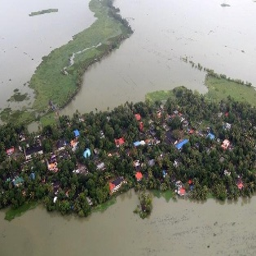

In [ ]:
im = Image.open('Disaster_Dataset/Flood/0010.jpg').resize((256, 256))
im

In [ ]:
for folder in os.listdir("Disaster_Dataset"):
    files = gb.glob(pathname= str("Disaster_Dataset//"+folder + "/*.jpg"))
    print(f" {len(files)} images are found in '{folder}' folder.")

 928 images are found in 'Cyclone' folder.
 1350 images are found in 'Earthquake' folder.
 1073 images are found in 'Flood' folder.
 1077 images are found in 'Wildfire' folder.


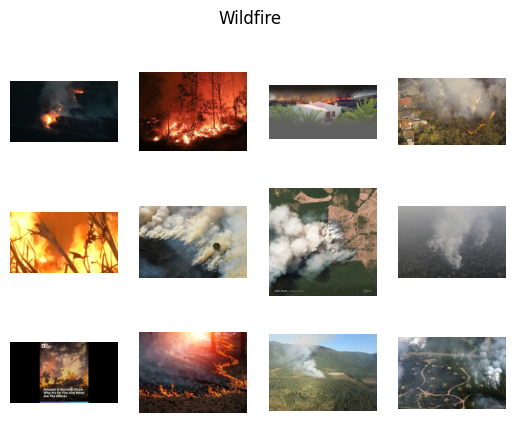

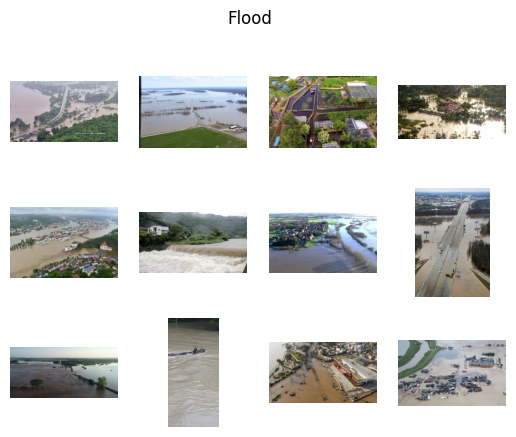

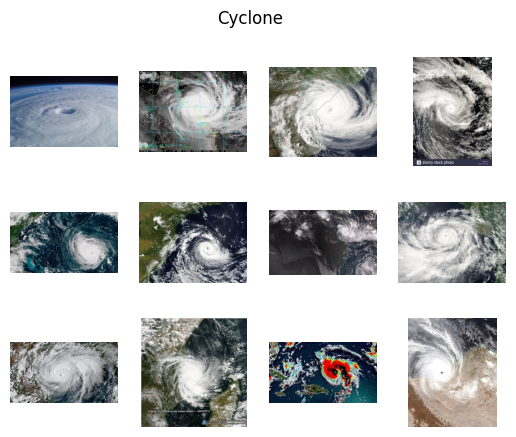

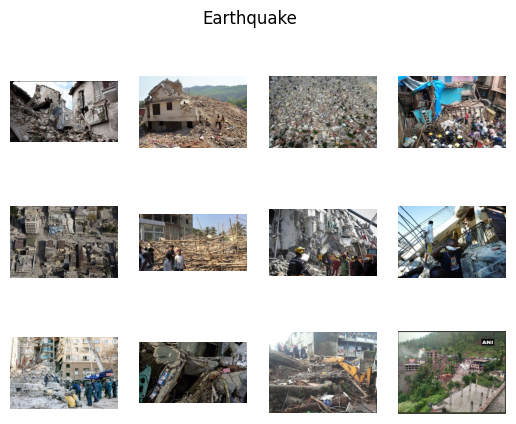

In [ ]:
path = 'Disaster_Dataset/'

categories = ['Wildfire', 'Flood', 'Cyclone', 'Earthquake']
num_class = len(categories)

for category in categories:
    fig, _ = plt.subplots(3,4)
    fig.suptitle(category)
    for k, v in enumerate(os.listdir(path+category)[:12]):
        img = plt.imread(path+category+'/'+v)
        plt.subplot(3, 4, k+1)
        plt.axis('off')
        plt.imshow(img)
    plt.show()

In [ ]:
from pathlib import Path
def proc_img(filepath):
    """ Create a DataFrame with the filepath and the labels of the images
    """

    labels = list(map(lambda x: os.path.split(os.path.split(x)[0])[1], filepath))

    filepath = pd.Series(filepath, name='Filepath').astype(str)
    labels = pd.Series(labels, name='Label')

    # Concatenate filepaths and labels
    df = pd.concat([filepath, labels], axis=1)

    # Shuffle the DataFrame and reset index
    df = df.sample(frac=1).reset_index(drop = True)

    return df

# Create a list with the filepaths
train_dir = Path('Disaster_Dataset')
filepaths = list(train_dir.glob(r'**/*.jpg'))

# Create a DataFrame with the filepaths and the labels of the picture
df = proc_img(filepaths)

print(f'Number of Images: {df.shape[0]}\n')
print(f'Number of different labels: {len(df.Label.unique())}\n')
print(f'Labels: {df.Label.unique()}')

# The DataFrame with the filepaths in one column and the labels in the other one
df.head(5)

Number of Images: 4428

Number of different labels: 4

Labels: ['Cyclone' 'Wildfire' 'Flood' 'Earthquake']


,Filepath,Label
0,Disaster_Dataset/Cyclone/0399.jpg,Cyclone
1,Disaster_Dataset/Cyclone/0782.jpg,Cyclone
2,Disaster_Dataset/Wildfire/0194.jpg,Wildfire
3,Disaster_Dataset/Cyclone/0516.jpg,Cyclone
4,Disaster_Dataset/Flood/0388.jpg,Flood


In [ ]:
# Separate in train and test data
from sklearn.model_selection import train_test_split
train_df, test_df = train_test_split(df, train_size=0.8, shuffle=True, random_state=0)

In [ ]:
train_generator = tf.keras.preprocessing.image.ImageDataGenerator(
    preprocessing_function=tf.keras.applications.mobilenet_v2.preprocess_input,
    validation_split=0.2
)

test_generator = tf.keras.preprocessing.image.ImageDataGenerator(
    preprocessing_function=tf.keras.applications.mobilenet_v2.preprocess_input
)

### Loading the images

In [ ]:
train_images = train_generator.flow_from_dataframe(
    dataframe=train_df,
    x_col='Filepath',
    y_col='Label',
    target_size=(224, 224),
    color_mode='rgb',
    class_mode='categorical',
    batch_size=16,
    shuffle=True,
    seed=0,
    subset='training',
    rotation_range=30,
    zoom_range=0.15,
    width_shift_range=0.2,
    height_shift_range=0.2,
    shear_range=0.15,
    horizontal_flip=True,
    fill_mode="nearest"
)

val_images = train_generator.flow_from_dataframe(
    dataframe=train_df,
    x_col='Filepath',
    y_col='Label',
    target_size=(224, 224),
    color_mode='rgb',
    class_mode='categorical',
    batch_size=16,
    shuffle=True,
    seed=0,
    subset='validation',
    rotation_range=30,
    zoom_range=0.15,
    width_shift_range=0.2,
    height_shift_range=0.2,
    shear_range=0.15,
    horizontal_flip=True,
    fill_mode="nearest"
)
test_images = test_generator.flow_from_dataframe(
    dataframe=test_df,
    x_col='Filepath',
    y_col='Label',
    target_size=(224, 224),
    color_mode="rgb",
    class_mode='categorical',
    batch_size=16,
    shuffle=False
)

Found 2834 validated image filenames belonging to 4 classes.
Found 708 validated image filenames belonging to 4 classes.
Found 886 validated image filenames belonging to 4 classes.


In [ ]:
train_filepaths = set(train_df['Filepath'])
test_filepaths = set(test_df['Filepath'])

overlap = train_filepaths.intersection(test_filepaths)

if not overlap:
    print(f"No data leakage detected. The training and test sets are mutually exclusive.")
else:
    print(f"Data leakage detected! There are {len(overlap)} overlapping images.\nFirst 5 overlapping paths: {list(overlap)[:5]}")

No data leakage detected. The training and test sets are mutually exclusive.


### Enhanced Data Leakage Check using SHA256 Hashes


In [ ]:
import hashlib

def calculate_sha256(filepath):
    """Calculates the SHA256 hash of a file."""
    hasher = hashlib.sha256()
    try:
        with open(filepath, 'rb') as f:
            while True:
                chunk = f.read(4096)  # Read file in chunks
                if not chunk:
                    break
                hasher.update(chunk)
        return hasher.hexdigest()
    except FileNotFoundError:
        return None

# Example usage with an image from your dataset
# Using a path from the test_df to ensure it exists for demonstration
example_image_path = test_df['Filepath'].iloc[0]
image_hash = calculate_sha256(example_image_path)

if image_hash:
    print(f"SHA256 hash of '{example_image_path}':\n{image_hash}")
else:
    print(f"Could not find file: {example_image_path}")

SHA256 hash of 'Disaster_Dataset/Cyclone/0762.jpg':
7a6e6f6417f58127b827ccd490cbf85f2f5272b95a0cc01813a8221480a032ce


In [ ]:
# Calculate SHA256 hashes for all images in the training set
print("Calculating hashes for training images...")
train_hashes = {calculate_sha256(fp): fp for fp in train_df['Filepath'] if calculate_sha256(fp) is not None}

# Calculate SHA256 hashes for all images in the test set
print("Calculating hashes for test images...")
test_hashes = {calculate_sha256(fp): fp for fp in test_df['Filepath'] if calculate_sha256(fp) is not None}

# Find overlapping hashes
overlapping_hashes = set(train_hashes.keys()).intersection(set(test_hashes.keys()))

if not overlapping_hashes:
    print("\nNo data leakage detected based on SHA256 hashes. Training and test sets have unique image content.")
else:
    print(f"\nData leakage detected! There are {len(overlapping_hashes)} overlapping image contents.\n")
    print("First 5 overlapping image content pairs (train_path, test_path):")
    for i, hash_val in enumerate(list(overlapping_hashes)[:5]):
        print(f"  - Train: {train_hashes[hash_val]}, Test: {test_hashes[hash_val]}")

print("\nHash-based data leakage check complete.")

Calculating hashes for training images...
Calculating hashes for test images...

No data leakage detected based on SHA256 hashes. Training and test sets have unique image content.

Hash-based data leakage check complete.


### Define the data generator

In [ ]:
def count_of_images(dir_path):
    path, dirs, files = next(os.walk(dir_path))
    return len(files)

In [ ]:
Wildfire_count = count_of_images(path+"Wildfire/")
Flood_count = count_of_images(path+"Flood/")
Cyclone_count = count_of_images(path+"Cyclone/")
Earthquake_count = count_of_images(path+"Earthquake/")

In [ ]:
number_of_classes =  [Wildfire_count, Flood_count, Cyclone_count, Earthquake_count]

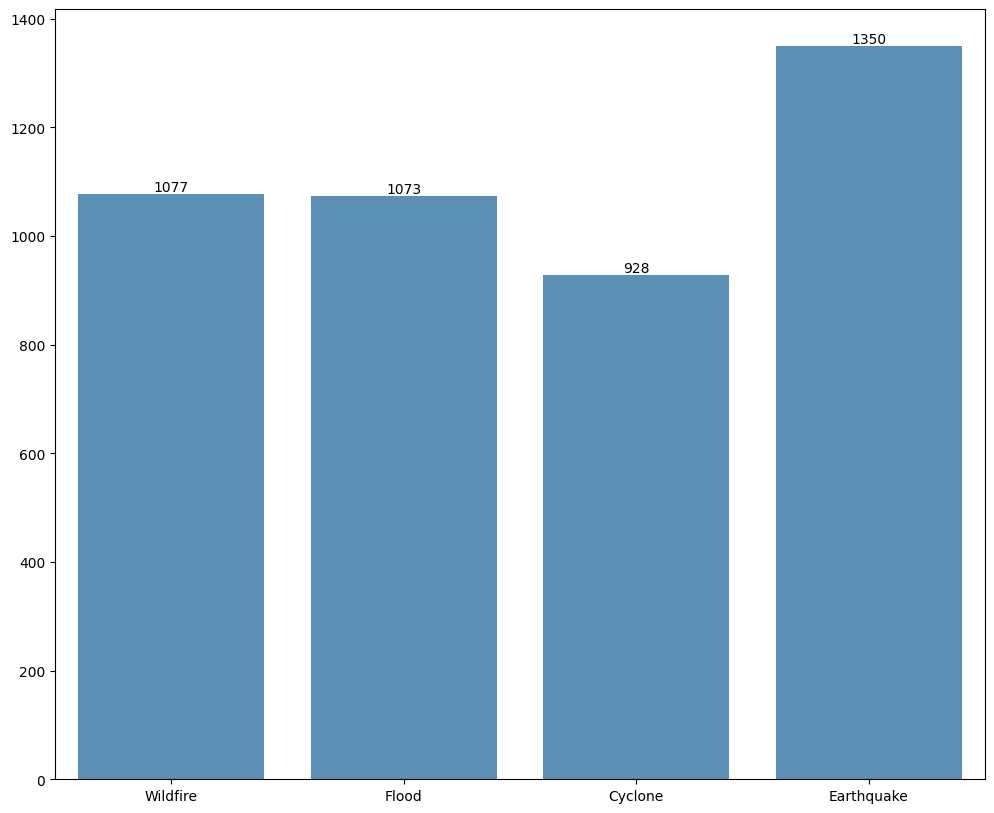

In [ ]:
plt.figure(figsize=(12,10))
sns.barplot(x=categories, y=number_of_classes, alpha=0.8)
for index, value in enumerate(number_of_classes):
    plt.text(index, value, str(value), ha='center', va='bottom')
plt.show()

### Check images size

In [ ]:
image_size=[]
for folder in os.listdir(path+"Wildfire"):
    files=gb.glob(pathname=str(path + "Wildfire//"+folder +"/*.jpg"))
    for file in files:
        image=plt.imread(file)
        image_size.append(image.shape)
pd.Series(image_size).value_counts()

,count



### Hybrid CNN-GNN with Gated Attention Transformer Model

In [ ]:
# CNN branch (InceptionV3)
cnn_backbone = tf.keras.applications.InceptionV3(include_top=False, input_shape=(224,224,3), weights='imagenet')

87910968/87910968 ━━━━━━━━━━━━━━━━━━━━ 5s 0us/step


In [ ]:
import tensorflow as tf
from tensorflow.keras import layers, Model, Input
import keras.ops # Import keras.ops

def stem_block(x):
    x = layers.Conv2D(32,3, strides=2, padding='same', activation='relu')(x)
    x = layers.Conv2D(64,3, strides=2, padding='same', activation='relu')(x)
    return x

def patchify_and_embed(x, patch_size=16, dim=64):
    # x: (B,H,W,C)
    p = layers.Conv2D(dim, kernel_size=patch_size, strides=patch_size, padding='same')(x)
    tokens = layers.Reshape((-1, dim))(p)  # (B, P, dim)
    return tokens

def lightweight_gnn(tokens, k=4, dim=64):
    # tokens: (B,P,dim)
    q = layers.Dense(dim)(tokens)
    kproj = layers.Dense(dim)(tokens)
    # Explicitly transpose
    logits = keras.ops.matmul(q, keras.ops.transpose(kproj, axes=(0, 2, 1)))  # (B,P,P)
    att = keras.ops.softmax(logits, axis=-1)
    # optional top-k sparsify here
    m = keras.ops.matmul(att, tokens)   # aggregated neighbor messages
    out = layers.Dense(dim, activation='relu')(layers.Concatenate()([tokens, m]))
    return out  # (B,P,dim)

def cross_attention_gate(src, tgt, dim=256):
    # src gates tgt: compute attn(src->tgt) then sigmoid gate
    att = layers.MultiHeadAttention(num_heads=4, key_dim=dim//4)(tgt, src) # (B,P,dim)
    gate = layers.Dense(dim, activation='sigmoid')(layers.LayerNormalization()(att))
    gated = layers.Multiply()([tgt, gate])
    return gated

def CAGB(cnn_feat, tokens, gnn_tokens, dim=256):

    # Project all inputs to the common fusion dimension 'dim' (256)
    cnn_feat_projected = layers.Dense(dim, name='cnn_feat_proj')(cnn_feat) # (B, dim)
    tokens_projected = layers.Dense(dim, name='tokens_proj')(tokens)     # (B, P, dim)
    gnn_tokens_projected = layers.Dense(dim, name='gnn_tokens_proj')(gnn_tokens) # (B, P, dim)

    # cross gating operations using the projected features
    gated_cnn = cross_attention_gate(tokens_projected, keras.ops.expand_dims(cnn_feat_projected, 1), dim)
    gated_cnn = layers.GlobalAveragePooling1D()(gated_cnn) # (B, dim)

    gated_t = cross_attention_gate(keras.ops.expand_dims(cnn_feat_projected, 1), tokens_projected, dim)
    gated_t = layers.GlobalAveragePooling1D()(gated_t) # (B, dim)

    gated_g = cross_attention_gate(tokens_projected, gnn_tokens_projected, dim)
    gated_g = layers.GlobalAveragePooling1D()(gated_g) # (B, dim)

    fused = layers.Concatenate()([gated_cnn, gated_t, gated_g]) # (B, 3*dim)
    fused = layers.Dense(dim, activation='relu')(fused) # (B, dim)
    return fused  # (B, dim)

# build model
inp = Input((224,224,3))
x = stem_block(inp)

# CNN
cnn_feats_map = cnn_backbone(inp)  # (B, H, W, C)
cnn_pool = layers.GlobalAveragePooling2D()(cnn_feats_map)

# ViT tokens
tokens = patchify_and_embed(x, patch_size=16, dim=64)
# Transformer encoder stack
for _ in range(2):
    att = layers.MultiHeadAttention(4, key_dim=16)(tokens, tokens)
    tokens = layers.Add()([tokens, att])
    tokens = layers.LayerNormalization()(tokens)
    ff = layers.Dense(128, activation='gelu')(tokens)
    ff = layers.Dense(64)(ff)
    tokens = layers.Add()([tokens, ff])
    tokens = layers.LayerNormalization()(tokens)

# GNN over tokens
gnn_tokens = lightweight_gnn(tokens, k=6, dim=64)

# Fuse at single scale
fused = CAGB(cnn_pool, tokens, gnn_tokens, dim=256)

# Aggregate and classify
global_emb = layers.Dense(256, activation='relu')(fused)
logits = layers.Dense(num_class, activation='softmax')(global_emb)

model = Model(inp, logits)

In [ ]:
opt = tf.keras.optimizers.Adam(learning_rate=0.000001)
model.compile(optimizer=opt, loss='categorical_crossentropy', metrics=['accuracy'])

In [ ]:
model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1       │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_94 (Conv2D)  │ (None, 112, 112,  │        896 │ input_layer_1[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_95 (Conv2D)  │ (None, 56, 56,    │     18,496 │ conv2d_94[0][0]   │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_96 (Conv2D)  │ (None, 4, 4, 64)  │  1,048,640 │ conv2d_95[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ reshape (Reshape)   │ (None, 16, 64)    │          0 │ conv2d_96[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multi_head_attenti… │ (None, 16, 64)    │     16,640 │ reshape[0][0],    │
│ (MultiHeadAttentio… │                   │            │ reshape[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 16, 64)    │          0 │ reshape[0][0],    │
│                     │                   │            │ multi_head_atten… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalization │ (None, 16, 64)    │        128 │ add[0][0]         │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 16, 128)   │      8,320 │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 16, 64)    │      8,256 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_1 (Add)         │ (None, 16, 64)    │          0 │ layer_normalizat… │
│                     │                   │            │ dense_1[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 16, 64)    │        128 │ add_1[0][0]       │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multi_head_attenti… │ (None, 16, 64)    │     16,640 │ layer_normalizat… │
│ (MultiHeadAttentio… │                   │            │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_2 (Add)         │ (None, 16, 64)    │          0 │ layer_normalizat… │
│                     │                   │            │ multi_head_atten… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 16, 64)    │        128 │ add_2[0][0]       │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_2 (Dense)     │ (None, 16, 128)   │      8,320 │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_3 (Dense)     │ (None, 16, 64)    │      8,256 │ dense_2[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_3 (Add)         │ (None, 16, 64)    │          0 │ layer_normalizat… │
│                     │                   │            │ dense_3[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 16, 64)    │        128 │ add_3[0][0]     

 Total params: 24,764,260 (94.47 MB)

 Trainable params: 24,729,828 (94.34 MB)

 Non-trainable params: 34,432 (134.50 KB)

In [ ]:
# Plot and save model structure
plot_model(model, to_file="cnn_gnn_hcagt_model.png", show_shapes=True, expand_nested=False)

In [ ]:
history = model.fit(train_images, validation_data=val_images, batch_size=64, epochs=50, callbacks=None)

Epoch 1/50
178/178 ━━━━━━━━━━━━━━━━━━━━ 205s 558ms/step - accuracy: 0.3687 - loss: 1.3251 - val_accuracy: 0.4633 - val_loss: 1.2526
Epoch 2/50
178/178 ━━━━━━━━━━━━━━━━━━━━ 29s 163ms/step - accuracy: 0.5328 - loss: 1.1914 - val_accuracy: 0.6427 - val_loss: 1.1187
Epoch 3/50
178/178 ━━━━━━━━━━━━━━━━━━━━ 29s 165ms/step - accuracy: 0.6814 - loss: 1.0456 - val_accuracy: 0.7288 - val_loss: 0.9688
Epoch 4/50
178/178 ━━━━━━━━━━━━━━━━━━━━ 30s 168ms/step - accuracy: 0.7685 - loss: 0.9033 - val_accuracy: 0.7966 - val_loss: 0.8329
Epoch 5/50
178/178 ━━━━━━━━━━━━━━━━━━━━ 31s 173ms/step - accuracy: 0.8243 - loss: 0.7763 - val_accuracy: 0.8390 - val_loss: 0.7138
Epoch 6/50
178/178 ━━━━━━━━━━━━━━━━━━━━ 31s 176ms/step - accuracy: 0.8592 - loss: 0.6748 - val_accuracy: 0.8771 - val_loss: 0.6130
Epoch 7/50
178/178 ━━━━━━━━━━━━━━━━━━━━ 31s 172ms/step - accuracy: 0.8684 - loss: 0.5968 - val_accuracy: 0.9124 - val_loss: 0.5308
Epoch 8/50
178/178 ━━━━━━━━━━━━━━━━━━━━ 31s 174ms/step - accuracy: 0.8913 - loss: 

In [ ]:
def plot_result(history):
    f = plt.figure(figsize=(20,7))
    plt.subplot(121)
    plt.plot(history.history["accuracy"])
    plt.plot(history.history["val_accuracy"])
    plt.title("Model Training and validation Accuracy")
    plt.ylabel("accuracy")
    plt.xlabel("epoch")
    plt.legend(['training accuracy', 'validation Accuracy'], loc = "best")
    plt.subplot(122)
    plt.plot(history.history["loss"])
    plt.plot(history.history["val_loss"])
    plt.title("Model training and validation Loss")
    plt.ylabel("loss")
    plt.xlabel("epoch")
    plt.legend(["training loss", "validation loss"], loc = "upper right")
    plt.show()

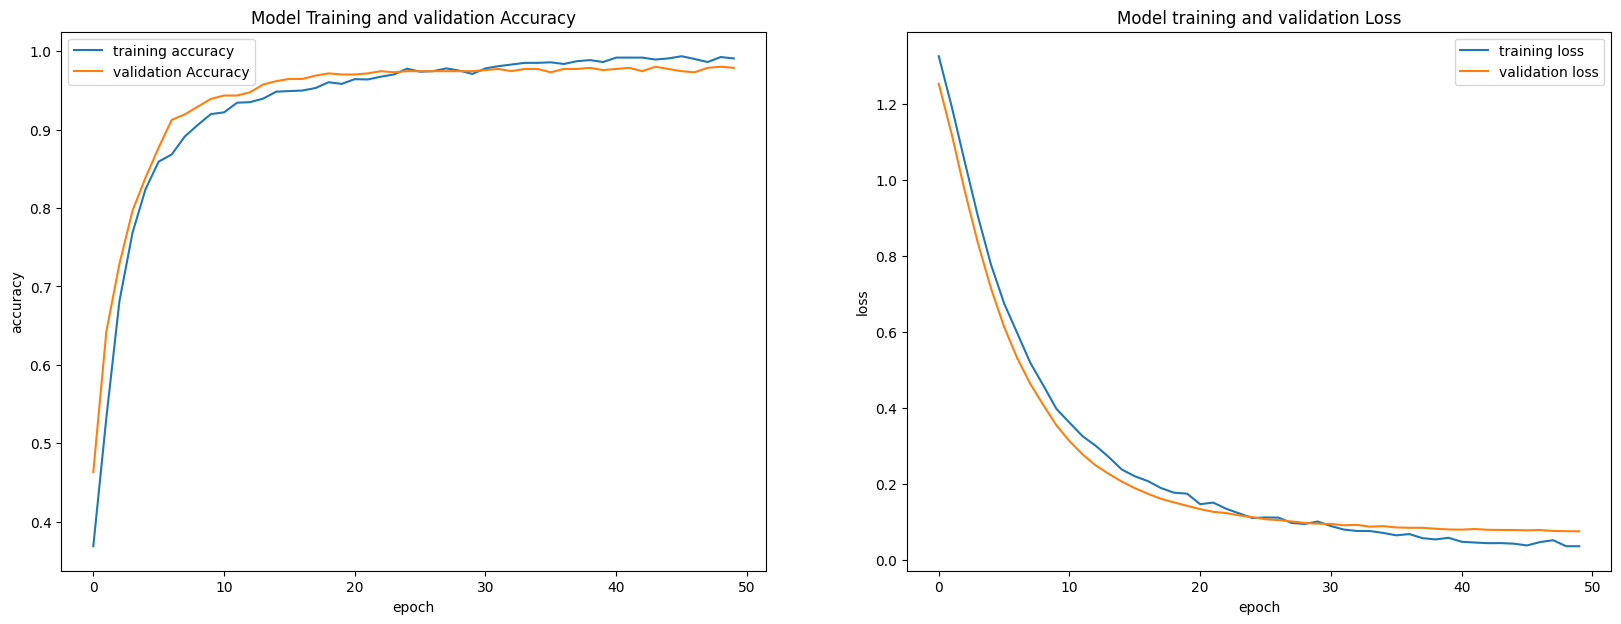

In [ ]:
plot_result(history)

In [ ]:
model = tf.keras.models.load_model("proposed_model.keras")

In [ ]:
print(" checkpoint loaded successfully.")

 checkpoint loaded successfully.


In [ ]:
testing_acc = model.evaluate(test_images)
print("the testing accuracy is :", testing_acc[1]*100, '%')

56/56 ━━━━━━━━━━━━━━━━━━━━ 10s 183ms/step - accuracy: 0.9616 - loss: 0.1263
the testing accuracy is : 96.16252779960632 %


In [ ]:
preds = model.predict(test_images,verbose = 1)

56/56 ━━━━━━━━━━━━━━━━━━━━ 17s 175ms/step


In [ ]:
# Predict the label of the test_images
pred = model.predict(test_images)
pred = np.argmax(pred,axis=1)

# Map the label
labels = (train_images.class_indices)
labels = dict((v,k) for k,v in labels.items())
pred = [labels[k] for k in pred]

# Display the result
print(f'The first 5 predictions: {pred[:5]}')

56/56 ━━━━━━━━━━━━━━━━━━━━ 2s 41ms/step
The first 5 predictions: ['Earthquake', 'Flood', 'Cyclone', 'Earthquake', 'Flood']


In [ ]:
y_test = list(test_df.Label)

In [ ]:
from sklearn.metrics import classification_report
class_report = classification_report(y_test, pred, digits=4)
print(class_report)

              precision    recall  f1-score   support

     Cyclone     1.0000    0.9648    0.9821       199
  Earthquake     0.9504    0.9710    0.9606       276
       Flood     0.9461    0.9279    0.9369       208
    Wildfire     0.9567    0.9803    0.9684       203

    accuracy                         0.9616       886
   macro avg     0.9633    0.9610    0.9620       886
weighted avg     0.9620    0.9616    0.9616       886



In [ ]:
from sklearn.metrics import classification_report
import pandas as pd

# Normal report for display
class_report = classification_report(y_test, pred, digits=4)

# Report as dictionary for CSV
class_report_dict = classification_report(
    y_test,
    pred,
    digits=4,
    output_dict=True
)

# Convert to DataFrame
class_report_df = pd.DataFrame(class_report_dict).transpose()

# Save CSV
class_report_df.to_csv(
    '/content/classification_report.csv'
)

print("\nClassification report CSV saved successfully.")


Classification report CSV saved successfully.


In [ ]:
Index = ["Cyclone", "Earthquake", "Flood", "Wildfire"]
column = ["Cyclone", "Earthquake", "Flood", "Wildfire"]

Text(0.5, 1.0, 'Confusion Matrix of Disaster Classification')

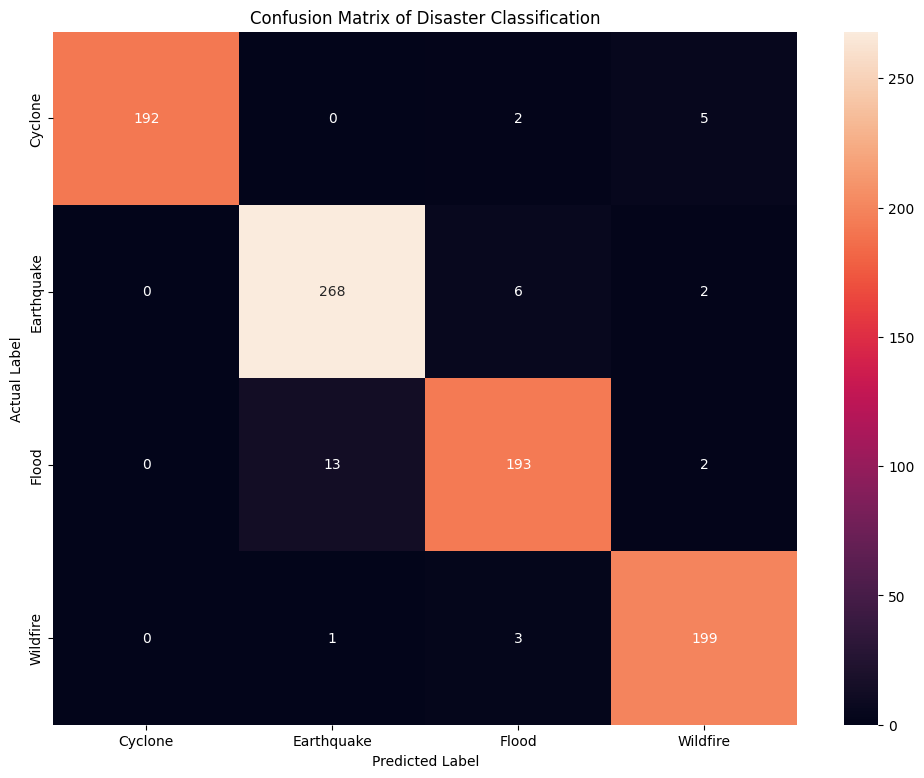

In [ ]:
from sklearn.metrics import confusion_matrix
plt.figure(figsize=(12,9))
cm = pd.DataFrame(data=confusion_matrix(y_test, pred),index=Index,columns=column)
sns.heatmap(cm, annot=True,fmt="d")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Confusion Matrix of Disaster Classification")

In [ ]:
from sklearn.metrics import confusion_matrix
import pandas as pd

# Class order
class_names = ['Cyclone', 'Earthquake', 'Flood', 'Wildfire']

# Calculate confusion matrix
cm = confusion_matrix(
    y_test,
    pred,
    labels=class_names
)

# Convert to DataFrame
cm_df = pd.DataFrame(
    cm,
    index=class_names,
    columns=class_names
)

# Save as CSV
cm_df.to_csv(
    '/content/confusion_matrix.csv'
)

# Display
print("\nCSV saved successfully:")
print("/content/confusion_matrix.csv")

CSV saved successfully:
/content/confusion_matrix.csv


### Predictions




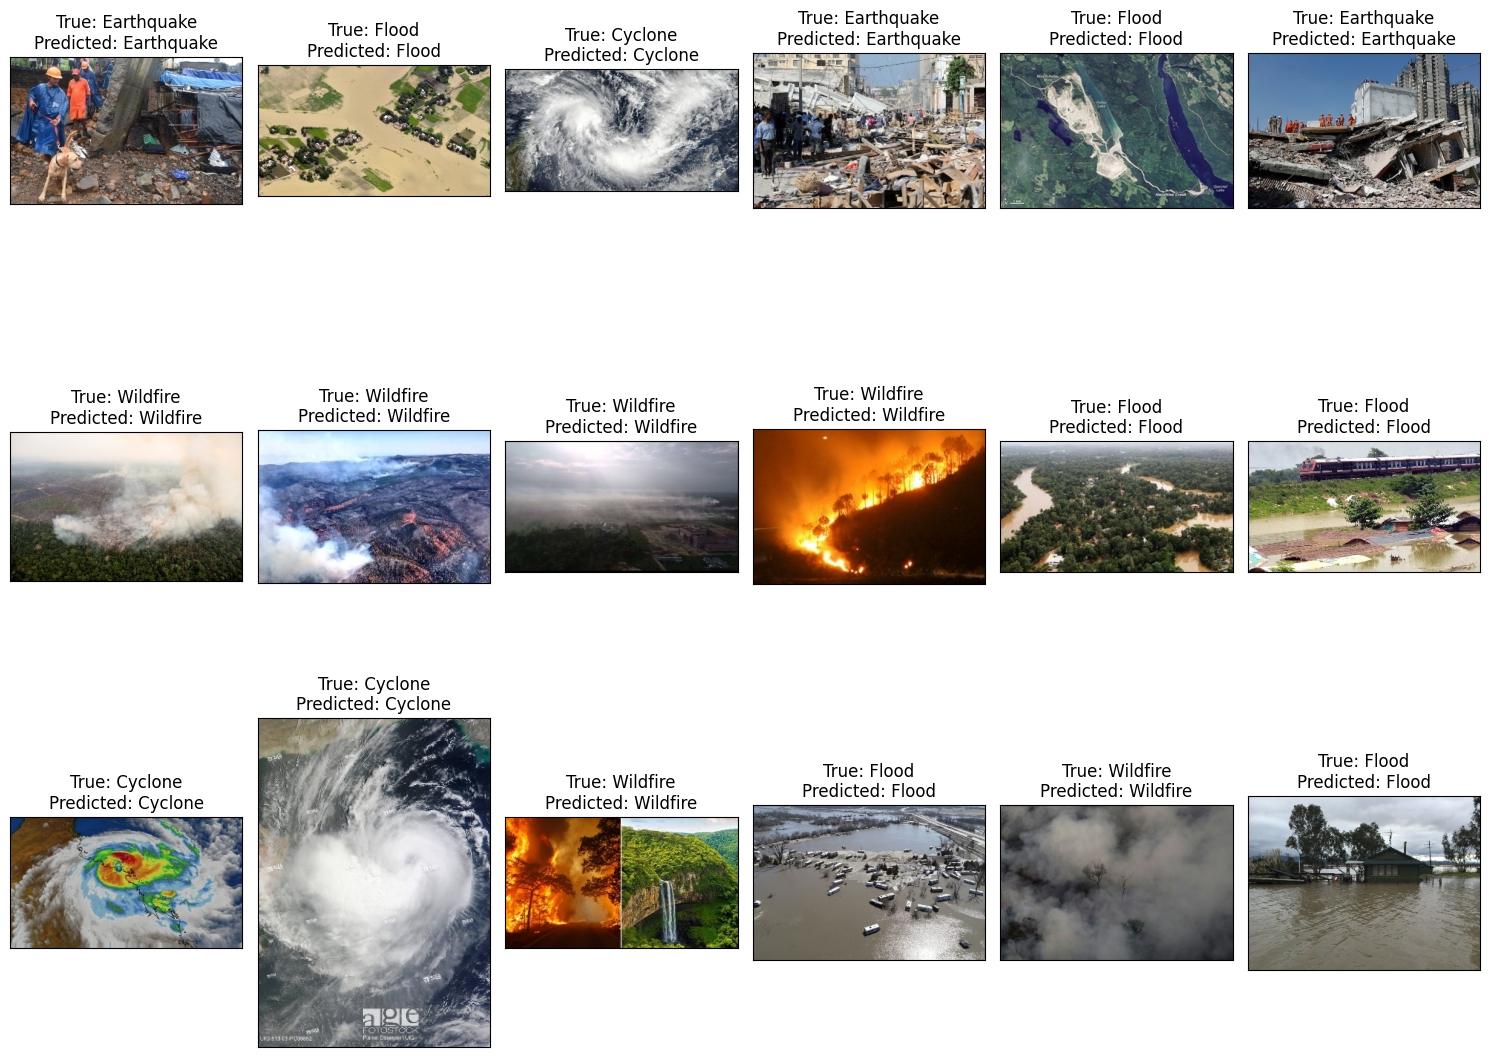

<Figure size 640x480 with 0 Axes>

In [ ]:
# Display 15 images of the dataset with their labels
fig, axes = plt.subplots(nrows=3, ncols=6, figsize=(15, 12),
                        subplot_kw={'xticks': [], 'yticks': []})

for i, ax in enumerate(axes.flat):
    ax.imshow(plt.imread(test_df.Filepath.iloc[i]))
    ax.set_title(f"True: {test_df.Label.iloc[i].split('_')[0]}\nPredicted: {pred[i].split('_')[0]}")
plt.tight_layout()
plt.show()
plt.savefig('plot2.png', dpi=300, bbox_inches='tight')

In [ ]:
from sklearn.metrics import roc_curve, auc
from sklearn.preprocessing import label_binarize
import matplotlib.pyplot as plt
import numpy as np

In [ ]:
y_test_bin = label_binarize(y_test, classes=np.unique(y_test))
n_classes = y_test_bin.shape[1]

In [ ]:
fpr = dict()
tpr = dict()
roc_auc = dict()
for i in range(n_classes):
    fpr[i], tpr[i], _ = roc_curve(y_test_bin[:, i], preds[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])

In [ ]:
fpr["micro"], tpr["micro"], _ = roc_curve(y_test_bin.ravel(), preds.ravel())
roc_auc["micro"] = auc(fpr["micro"], tpr["micro"])

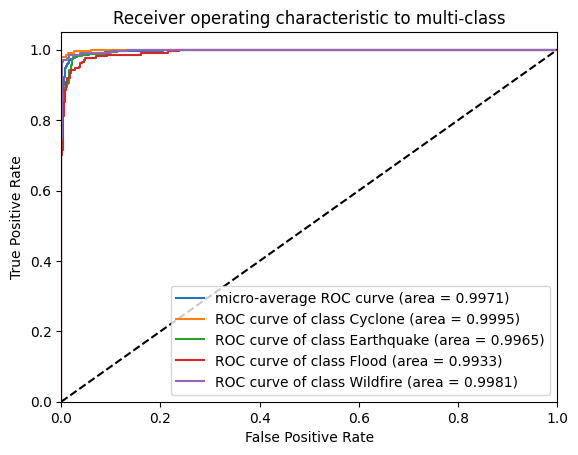

In [ ]:
# Get class names from the train_images generator
class_names = list(train_images.class_indices.keys())

# Plot the ROC curves with class names
plt.figure()
plt.plot(fpr["micro"], tpr["micro"],
         label='micro-average ROC curve (area = {0:0.4f})'
               ''.format(roc_auc["micro"]))
for i in range(n_classes):
    plt.plot(fpr[i], tpr[i], label='ROC curve of class {0} (area = {1:0.4f})'
                                   ''.format(class_names[i], roc_auc[i]))

plt.plot([0, 1], [0, 1], 'k--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver operating characteristic to multi-class')
plt.legend(loc="lower right")
plt.show()

Test prediction file

In [ ]:
# Reset test generator to ensure predictions start from the first test image
test_images.reset()

# Get prediction probabilities for all test images
pred_probs = model.predict(test_images, verbose=1)

# Get predicted class index
pred_indices = np.argmax(pred_probs, axis=1)

# Keep class-to-index mapping for column slicing
class_to_idx = train_images.class_indices

# Create index-to-class mapping for prediction labels
idx_to_class = dict((v, k) for k, v in class_to_idx.items())
pred_labels = [idx_to_class[i] for i in pred_indices]

# True labels from the test dataframe
true_labels = list(test_df['Label'])

# Create prediction dataframe
prediction_df = pd.DataFrame({
    'Filename': test_df['Filepath'].values,
    'True_Label': true_labels,
    'Predicted_Label': pred_labels,

})

# Save CSV
prediction_df.to_csv(
    'test_predictions_seed0.csv',
    index=False
)

print("CSV created successfully.")


56/56 ━━━━━━━━━━━━━━━━━━━━ 15s 261ms/step
CSV created successfully.


Individual Predictions

1/1 ━━━━━━━━━━━━━━━━━━━━ 10s 10s/step


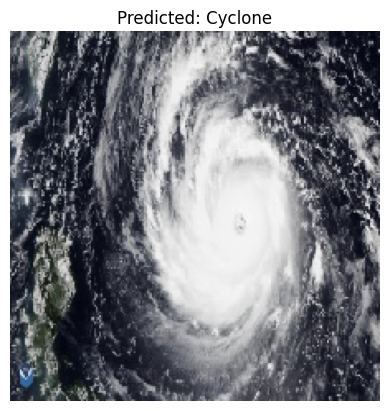

In [ ]:
image_path = 'Disaster_Dataset/Cyclone/0032.jpg'

# Load and preprocess the image
img = load_img(image_path, target_size=(224, 224))
img_array = img_to_array(img)
img_array = np.expand_dims(img_array, axis=0)
img_array = tf.keras.applications.mobilenet_v2.preprocess_input(img_array)

# Make prediction
prediction = model.predict(img_array)

# Get the predicted class index
predicted_class_index = np.argmax(prediction)

# Map the index to the class name
predicted_class_name = labels[predicted_class_index]

# Display the image and prediction
plt.imshow(img)
plt.title(f"Predicted: {predicted_class_name}")
plt.axis('off')
plt.show()

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 59ms/step


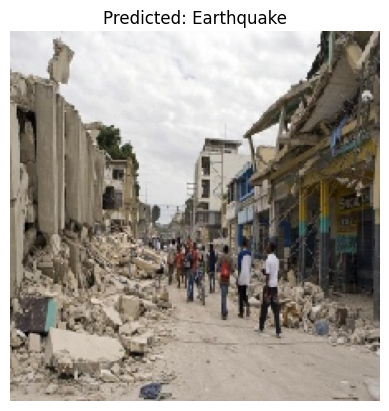

In [ ]:
image_path = 'Disaster_Dataset/Earthquake/0006.jpg'

# Load and preprocess the image
img = load_img(image_path, target_size=(224, 224))
img_array = img_to_array(img)
img_array = np.expand_dims(img_array, axis=0)
img_array = tf.keras.applications.mobilenet_v2.preprocess_input(img_array)

# Make prediction
prediction = model.predict(img_array)

# Get the predicted class index
predicted_class_index = np.argmax(prediction)

# Map the index to the class name
predicted_class_name = labels[predicted_class_index]

# Display the image and prediction
plt.imshow(img)
plt.title(f"Predicted: {predicted_class_name}")
plt.axis('off')
plt.show()

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 60ms/step


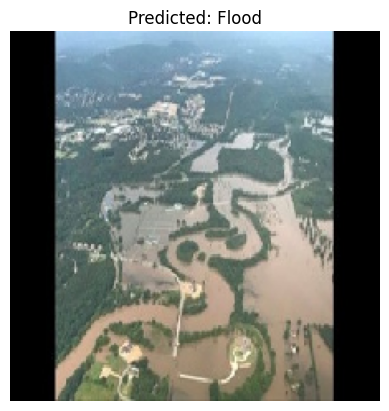

In [ ]:
image_path = 'Disaster_Dataset/Flood/0005.jpg'

# Load and preprocess the image
img = load_img(image_path, target_size=(224, 224))
img_array = img_to_array(img)
img_array = np.expand_dims(img_array, axis=0)
img_array = tf.keras.applications.mobilenet_v2.preprocess_input(img_array)

# Make prediction
prediction = model.predict(img_array)

# Get the predicted class index
predicted_class_index = np.argmax(prediction)

# Map the index to the class name
predicted_class_name = labels[predicted_class_index]

# Display the image and prediction
plt.imshow(img)
plt.title(f"Predicted: {predicted_class_name}")
plt.axis('off')
plt.show()

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 60ms/step


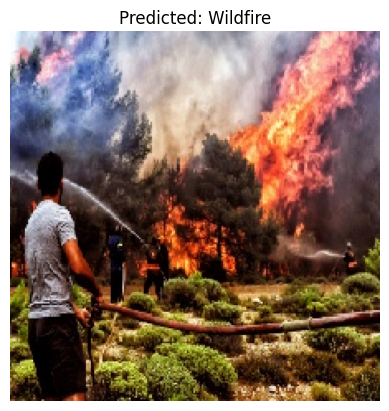

In [ ]:
image_path = 'Disaster_Dataset/Wildfire/0002.jpg'

# Load and preprocess the image
img = load_img(image_path, target_size=(224, 224))
img_array = img_to_array(img)
img_array = np.expand_dims(img_array, axis=0)
img_array = tf.keras.applications.mobilenet_v2.preprocess_input(img_array)

# Make prediction
prediction = model.predict(img_array)

# Get the predicted class index
predicted_class_index = np.argmax(prediction)

# Map the index to the class name
predicted_class_name = labels[predicted_class_index]

# Display the image and prediction
plt.imshow(img)
plt.title(f"Predicted: {predicted_class_name}")
plt.axis('off')
plt.show()

In [ ]:
from sklearn.metrics import classification_report
from sklearn.metrics import roc_curve, auc
from sklearn.preprocessing import label_binarize
import numpy as np

# Define y_test
y_test = list(test_df.Label)

# Binarize y_test for ROC AUC calculation
y_test_bin = label_binarize(y_test, classes=np.unique(y_test))
n_classes = y_test_bin.shape[1]

# Calculate ROC curve and AUC for each class
fpr = dict()
tpr = dict()
roc_auc = dict()
for i in range(n_classes):
    fpr[i], tpr[i], _ = roc_curve(y_test_bin[:, i], preds[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])

# Calculate micro-average ROC curve and AUC
fpr["micro"], tpr["micro"], _ = roc_curve(y_test_bin.ravel(), preds.ravel())
roc_auc["micro"] = auc(fpr["micro"], tpr["micro"])


# Display the classification report
class_report = classification_report(y_test, pred, output_dict=True)
print("Classification Report:\n")
print(classification_report(y_test, pred, digits=4))

# Display individual metrics
print("\nMetrics:")
print(f"  Accuracy: {class_report['accuracy']:.4f}")
print(f"  Precision (macro avg): {class_report['macro avg']['precision']:.4f}")
print(f"  Recall (macro avg): {class_report['macro avg']['recall']:.4f}")
print(f"  F1-score (macro avg): {class_report['macro avg']['f1-score']:.4f}")

# Display ROC AUC scores
print("\nROC AUC Scores:")
class_names = list(train_images.class_indices.keys())
for i in range(n_classes):
    print(f"  {class_names[i]}: {roc_auc[i]:.4f}")
print(f"  Micro-average ROC AUC: {roc_auc['micro']:.4f}")

Classification Report:

              precision    recall  f1-score   support

     Cyclone     1.0000    0.9648    0.9821       199
  Earthquake     0.9504    0.9710    0.9606       276
       Flood     0.9461    0.9279    0.9369       208
    Wildfire     0.9567    0.9803    0.9684       203

    accuracy                         0.9616       886
   macro avg     0.9633    0.9610    0.9620       886
weighted avg     0.9620    0.9616    0.9616       886


Metrics:
  Accuracy: 0.9616
  Precision (macro avg): 0.9633
  Recall (macro avg): 0.9610
  F1-score (macro avg): 0.9620

ROC AUC Scores:
  Cyclone: 0.9995
  Earthquake: 0.9965
  Flood: 0.9933
  Wildfire: 0.9981
  Micro-average ROC AUC: 0.9971


In [ ]:
#json file
import os, sys, json, datetime
import numpy as np, pandas as pd, tensorflow as tf, keras, sklearn, cv2, matplotlib
from sklearn.metrics import classification_report, confusion_matrix

os.makedirs("configs", exist_ok=True)
os.makedirs("results", exist_ok=True)

class_names = list(train_images.class_indices.keys())
rep = classification_report(y_test, pred, labels=class_names, output_dict=True, zero_division=0)
cm = confusion_matrix(y_test, pred, labels=class_names)
hist = history.history

config = {
    "experiment_name": "Disaster_Image_Classification",
    "model_name": "Cross-Attention Guided CNN-Transformer-GNN",
    "created_at": datetime.datetime.now().isoformat(timespec="seconds"),
    "random_seed": 0,

    "dataset": {
        "total_images": len(df),
        "images_per_class": {k: int(v) for k, v in df["Label"].value_counts().items()},
        "train_images": train_images.n,
        "validation_images": val_images.n,
        "test_images": test_images.n,
    },

    "preprocessing": {
        "image_size": list(train_images.target_size),
        "preprocess_function": "tf.keras.applications.mobilenet_v2.preprocess_input",
        "normalization": "[-1, 1]",
        "class_indices": train_images.class_indices,
    },

    "training": {
        "optimizer": model.optimizer.__class__.__name__,
        "learning_rate": float(keras.ops.convert_to_numpy(model.optimizer.learning_rate)),
        "loss_function": "categorical_crossentropy",
        "batch_size": train_images.batch_size,
        "epochs_run": len(hist["loss"]),
        "final_train_accuracy": float(hist["accuracy"][-1]),
        "final_val_accuracy": float(hist["val_accuracy"][-1]),
        "best_val_accuracy": float(max(hist["val_accuracy"])),
    },

    "test_metrics": {
        "accuracy": float(rep["accuracy"]),
        "macro_precision": float(rep["macro avg"]["precision"]),
        "macro_recall": float(rep["macro avg"]["recall"]),
        "macro_f1": float(rep["macro avg"]["f1-score"]),
        "confusion_matrix": {"labels": class_names, "matrix": cm.tolist()},
    },

    "environment": {
        "python_version": sys.version.split()[0],
        "tensorflow_version": tf.__version__,
        "keras_version": keras.__version__,
        "numpy_version": np.__version__,
        "pandas_version": pd.__version__,
        "scikit_learn_version": sklearn.__version__,
        "opencv_version": cv2.__version__,
        "matplotlib_version": matplotlib.__version__,
    },

    "artifacts": {
        "checkpoint_path": "checkpoints/proposed_seed0.keras",
        "training_history_path": "results/training_history_seed0.csv",
    },
}

# Save JSON
output_path = "configs/seed0_config.json"
with open(output_path, "w", encoding="utf-8") as f:
    json.dump(config, f, indent=4)
print(open(output_path).read())

# Save training history (not stored in the .keras file)
pd.DataFrame(hist).rename_axis("epoch").to_csv("results/training_history_seed0.csv")

# Download
from google.colab import files
files.download(output_path)


Model variable not found. Load or train the model first.

========== JSON CONFIGURATION ==========

{
    "experiment_name": "Disaster_Image_Classification",
    "model_name": "Cross-Attention Guided CNN-Transformer-GNN",
    "created_at": "2026-10-09T15:40:51",
    "random_seed": 0,
    "dataset": {
        "total_images": 4428,
        "images_per_class": {
            "Earthquake": 1350,
            "Wildfire": 1077,
            "Flood": 1073,
            "Cyclone": 928
        },
        "train_images": 2834,
        "validation_images": 708,
        "test_images": 886
    },
    "preprocessing": {
        "image_size": [
            224,
            224
        ],
        "color_mode": "rgb",
        "preprocess_function": "tf.keras.applications.mobilenet_v2.preprocess_input",
        "normalization": "[-1, 1]",
        "class_indices": {
            "Cyclone": 0,
            "Earthquake": 1,
            "Flood": 2,
            "Wildfire": 3
        },
        "augmentation": {
  

In [ ]:
import os
import tensorflow as tf
from google.colab import files

# 1. Save the trained model
os.makedirs("checkpoints", exist_ok=True)
checkpoint_path = "checkpoints/proposed_seed0.keras"   # same name as in the config JSON
model.save(checkpoint_path)

# 2. Check that it reloads and gives the same test accuracy
reloaded = tf.keras.models.load_model(checkpoint_path)
test_images.reset()
loss, acc = reloaded.evaluate(test_images, verbose=0)
print(f"Saved: {checkpoint_path}  ({os.path.getsize(checkpoint_path)/1e6:.1f} MB)")
#print(f"Reloaded model test accuracy: {acc*100:.2f}%")

# 3. Download
files.download(checkpoint_path)

Saved: checkpoints/proposed_seed0.keras  (298.4 MB)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

# README.md


import os, sys, hashlib, datetime
import numpy as np, pandas as pd, tensorflow as tf, keras, sklearn, matplotlib, cv2
from sklearn.metrics import classification_report, confusion_matrix, roc_curve, auc
from sklearn.preprocessing import label_binarize

# ---------- Class info ----------
class_indices = train_images.class_indices                      # {'Cyclone': 0, ...}
class_names = [c for c, _ in sorted(class_indices.items(), key=lambda kv: kv[1])]
idx_to_class = {v: k for k, v in class_indices.items()}

# ---------- Dataset statistics (uses the notebook's own `df`) ----------
class_counts = df["Label"].value_counts().reindex(class_names)
n_total, n_train, n_val, n_test = len(df), train_images.n, val_images.n, test_images.n

# ---------- Model statistics ----------
total_params = model.count_params()
trainable_params = int(sum(np.prod(w.shape) for w in model.trainable_weights))
non_trainable_params = total_params - trainable_params
lr = float(keras.ops.convert_to_numpy(model.optimizer.learning_rate))
opt_name = model.optimizer.__class__.__name__
loss_name = model.loss if isinstance(model.loss, str) else type(model.loss).__name__
hist = history.history
epochs_run = len(hist["loss"])
steps_per_epoch = len(train_images)
final_train_acc = hist["accuracy"][-1]
final_val_acc = hist["val_accuracy"][-1]
best_val_acc = max(hist["val_accuracy"])
best_epoch = int(np.argmax(hist["val_accuracy"])) + 1

# ---------- Test metrics ----------
rep = classification_report(y_test, pred, labels=class_names, output_dict=True, zero_division=0)
cm = confusion_matrix(y_test, pred, labels=class_names)
y_bin = label_binarize(y_test, classes=class_names)
aucs = {c: auc(*roc_curve(y_bin[:, i], preds[:, class_indices[c]])[:2])
        for i, c in enumerate(class_names)}
micro_auc = auc(*roc_curve(
    y_bin.ravel(), preds[:, [class_indices[c] for c in class_names]].ravel())[:2])

# most frequent confusion (off-diagonal maximum)
off = cm.copy()
np.fill_diagonal(off, 0)
r, c_ = np.unravel_index(np.argmax(off), off.shape)
top_error = f"{class_names[r]} predicted as {class_names[c_]} ({int(off[r, c_])} images)"

# ---------- Leakage check (SHA-256 of file contents) ----------
def _sha(fp):
    h = hashlib.sha256()
    with open(fp, "rb") as f:
        for chunk in iter(lambda: f.read(8192), b""):
            h.update(chunk)
    return h.hexdigest()

dup = len(set(map(_sha, train_df.Filepath)) & set(map(_sha, test_df.Filepath)))
path_overlap = len(set(train_df.Filepath) & set(test_df.Filepath))
if dup == 0 and path_overlap == 0:
    leak_note = ("Train and test file paths do not overlap, and a SHA-256 comparison of\n"
                 "file contents found no byte-identical images shared between the train\n"
                 "and test sets.")
else:
    leak_note = (f"**Warning:** {path_overlap} shared file paths and {dup} byte-identical "
                 "images appear in both train and test sets; remove duplicates before "
                 "splitting to avoid inflated test scores.")

# ---------- Augmentation ----------
gen = train_images.image_data_generator
zoom = (gen.zoom_range[1] - gen.zoom_range[0]) / 2 if gen.zoom_range else 0
applied = {
    "Rotation range": gen.rotation_range,
    "Zoom range": round(zoom, 4),
    "Width shift": gen.width_shift_range,
    "Height shift": gen.height_shift_range,
    "Shear range": gen.shear_range,
    "Horizontal flip": gen.horizontal_flip,
    "Fill mode": gen.fill_mode,
}
aug_active = any([gen.rotation_range, zoom, gen.width_shift_range,
                  gen.height_shift_range, gen.shear_range, gen.horizontal_flip])

if aug_active:
    aug_rows = "".join(f"| {k} | {v} |\n" for k, v in applied.items())
    aug_section = f"""online augmentation was applied :

| Augmentation | Value |
|---|---:|
{aug_rows}"""
    conclusion_aug = "trained with data augmentation"
else:
    intended = [("Rotation range", 30), ("Zoom range", 0.15), ("Width shift", 0.2),
                ("Height shift", 0.2), ("Shear range", 0.15),
                ("Horizontal flip", True), ("Fill mode", "nearest")]
    intended_rows = "".join(f"| {k} | {v} |\n" for k, v in intended)
    aug_section = f"""**data augmentation was applied in the reported run.**

.
The notebook describes online augmentation of training batches with these settings

| Augmentation | Intended value |
|---|---:|
{intended_rows}
Augmented images are generated on the fly , while batches are prepared, not saved, so the dataset always stays at 4,428 original images.
"""
    conclusion_aug = "trained with data augmentation"

# ---------- Markdown tables ----------
dataset_tbl = ("| Class | Images |\n|---|---:|\n"
               + "".join(f"| {c} | {int(n)} |\n" for c, n in class_counts.items())
               + f"| **Total** | **{n_total}** |")

class_map_tbl = ("| Class | Index |\n|---|---:|\n"
                 + "".join(f"| {c} | {class_indices[c]} |\n" for c in class_names).rstrip("\n"))

perclass_tbl = (
    "| Class | Precision | Recall | F1-score | ROC-AUC | Support |\n|---|---:|---:|---:|---:|---:|\n"
    + "".join(f"| {c} | {rep[c]['precision']:.4f} | {rep[c]['recall']:.4f} | "
             f"{rep[c]['f1-score']:.4f} | {aucs[c]:.4f} | {int(rep[c]['support'])} |\n"
             for c in class_names)
    + f"| **Macro average** | **{rep['macro avg']['precision']:.4f}** | "
      f"**{rep['macro avg']['recall']:.4f}** | **{rep['macro avg']['f1-score']:.4f}** | – | "
      f"**{int(rep['macro avg']['support'])}** |\n"
    + f"| **Weighted average** | **{rep['weighted avg']['precision']:.4f}** | "
      f"**{rep['weighted avg']['recall']:.4f}** | **{rep['weighted avg']['f1-score']:.4f}** | – | "
      f"**{int(rep['weighted avg']['support'])}** |")

cm_tbl = ("| Actual / Predicted | " + " | ".join(class_names) + " |\n|---|"
          + "---:|" * len(class_names) + "\n"
          + "\n".join(f"| **{class_names[i]}** | " + " | ".join(str(int(v)) for v in row) + " |"
                      for i, row in enumerate(cm)))

label_dict_str = "{" + ", ".join(f'{i}: "{idx_to_class[i]}"' for i in sorted(idx_to_class)) + "}"
pct = lambda x: f"{x * 100:.2f}%"

# ---------- Write README ----------
readme = f"""# Disaster Image Classification
## Cross-Attention Guided CNN–Transformer–GNN

Hybrid deep-learning model for classifying disaster images into
four categories: **{", ".join(class_names[:-1])}, and {class_names[-1]}**.

The framework combines CNN image features, Transformer token
representations, graph-based feature interactions, and a
Cross-Attention Gating Block (CAGB).

---

## Dataset

{dataset_tbl}

### Dataset Split

The data is first split 80/20 into train and test sets
(`train_test_split`, `random_state=0`). A further 20% of the training
portion is held out for validation (`validation_split=0.2`).

| Split | Images |
|---|---:|
| Training | {n_train} |
| Validation | {n_val} |
| Testing | {n_test} |
| **Total** | **{n_train + n_val + n_test}** |

### Data Leakage Check

{leak_note}

### Preprocessing

- Image size: 224 × 224 × 3
- Color mode: RGB`
- Pixel normalization: [-1, 1]
- Random seed: 0

### Class Mapping

{class_map_tbl}

---

## Data Augmentation

{aug_section}

---

## Proposed Model Architecture

### CNN Branch
- ImageNet-pretrained InceptionV3 backbone (`include_top=False`).
- Global average pooling for extracting image-level features.

### Transformer Branch
- Convolutional stem (two stride-2 convolutions, 32 and 64 filters).
- 16 × 16 patch embedding, token embedding dimension 64
  (16 tokens per image).
- Two Transformer encoder blocks (4 heads, key dimension 16).

### Graph Neural Network Branch
- Attention-based message passing across patch tokens
  (dense attention adjacency over all tokens; no top-k sparsification).
- Learns contextual relationships between image regions.

### Cross-Attention Gating Block (CAGB)
- Integrates CNN, Transformer, and graph-based representations,
  each projected to a common dimension of 256.
- Uses three cross-attention sigmoid gates (4 heads) for adaptive
  feature fusion.
- Fused representation is passed through Dense(256) layers and a
  four-class softmax classifier.

### Model Size

| | Parameters |
|---|---:|
| Total | {total_params:,} |
| Trainable | {trainable_params:,} |
| Non-trainable | {non_trainable_params:,} |

---

## Training Configuration

| Parameter | Value |
|---|---|
| Optimizer | {opt_name} |
| Learning rate | {lr:.6f} |
| Loss function | {loss_name} |
| Batch size | {train_images.batch_size} |
| Epochs run | {epochs_run} |
| Steps per epoch | {steps_per_epoch} |
| Random seed | 0 |
| Callbacks | None |
| Final training accuracy | {pct(final_train_acc)} |
| Final validation accuracy | {pct(final_val_acc)} |
| Best validation accuracy | {pct(best_val_acc)} (epoch {best_epoch}) |


---

## Test Results

| Metric | Value |
|---|---:|
| Test accuracy | **{pct(rep['accuracy'])}** |
| Macro precision | {pct(rep['macro avg']['precision'])} |
| Macro recall | {pct(rep['macro avg']['recall'])} |
| Macro F1-score | {pct(rep['macro avg']['f1-score'])} |
| Micro-average ROC-AUC | {micro_auc:.4f} |
| Total test images | {n_test} |

---

## Per-Class Classification Report

{perclass_tbl}

---

## Confusion Matrix

Rows represent actual classes and columns represent predicted classes.

{cm_tbl}


---

## Software Environment

| Package | Version |
|---|---|
| Python | {sys.version.split()[0]} |
| TensorFlow | {tf.__version__} |
| Keras | {keras.__version__} |
| NumPy | {np.__version__} |
| pandas | {pd.__version__} |
| scikit-learn | {sklearn.__version__} |
| OpenCV | {cv2.__version__} |
| Matplotlib | {matplotlib.__version__} |

The notebook was run in Google Colab.

---

"""

with open("README.md", "w", encoding="utf-8") as f:
    f.write(readme)
print("README.md generated:", os.path.abspath("README.md"))

# Optional: download in Colab
try:
    from google.colab import files
    files.download("README.md")
except ImportError:
    pass

README.md generated: /content/README.md


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>